---
title: "L3-09 · Optimization and learning"
short_title: "Optimization and learning"
subtitle: "Learning means walking downhill on a loss surface, one gradient step at a time; the step size decides whether the walk converges, and only data the model has not seen can tell whether the bottom it found is any good."
description: "Perform gradient descent steps on a loss, find the step sizes for which descent is stable on a quadratic, and explain with a validation set why a lower training loss is an incomplete test of success."
tags: [level-3, coursebook]
---

(lesson-l3-09)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 90 minutes  
**Big idea.** Learning means walking downhill on a loss surface, one gradient step at a time; the step size decides whether the walk converges, and only data the model has not seen can tell whether the bottom it found is any good.  
**Before this lesson.** [L3-06](#lesson-l3-06)  
**Lab.** [Variational circuits and gradients](../../labs/08-variational-gradients.ipynb)
:::

## What you will be able to do

- Write a mean squared error loss for a simple model and carry out gradient descent steps $w \leftarrow w - \eta\, \nabla L(w)$ by hand.
- Prove that gradient descent on a quadratic with curvatures $a_i$ converges exactly when $0 < \eta < 2/\max_i a_i$, and predict slow, good and divergent behavior from the step size.
- Explain, with training and validation errors, why the model with the lowest training loss can be the worst at prediction, and prove that training error cannot rise as nested models grow.

## Why this matters

A model with ten adjustable numbers can pass exactly through ten data points. Its training error is zero, a perfect score. Yet on fresh data from the same source it can be worse than a straight line. If "lower loss" were the definition of success, we would always choose the model that memorizes, and we would be wrong.

Most of modern machine learning, and the variational quantum algorithms of Level 7, rest on one simple procedure: compute how the loss changes with each parameter, then step downhill. This lesson makes that procedure exact on problems small enough to solve by hand, shows the precise condition under which it converges, and then asks the harder question of what a low loss actually proves.

:::{dropdown} Key terms

**Loss function**
: A number $L(w)$ that measures how badly a model with parameters $w$ fits the data, for example the mean squared error.

**Gradient descent**
: The iteration $w \leftarrow w - \eta\, \nabla L(w)$, a step against the gradient, the direction of steepest increase.

**Step size (learning rate)**
: The positive number $\eta$ that scales each gradient step.

**Training and validation sets**
: Data used to fit the parameters, and separate data held back to estimate how well the fitted model predicts new cases.

**Overfitting**
: Fitting the training data, including its noise, so closely that predictions on new data get worse.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_09 as _lessonfigs

## Learning as minimizing a loss

A model makes a prediction $\hat y = f_w(x)$ that depends on parameters $w$. For data $(x_1, y_1), \dots, (x_n, y_n)$ we measure the misfit with a loss and choose $w$ to make it small [@mml].

:::{prf:definition} Mean squared error (training loss)
:label: def-l3-09-mse
The **mean squared error** of parameters $w$ on data $(x_i, y_i)_{i=1}^n$ is the average squared residual. Computed on the data used for fitting, it is the **training loss**.
:::

$$
L(w) = \frac{1}{n}\sum_{i=1}^{n} \big(f_w(x_i) - y_i\big)^2
$$ (eq-l3-09-mse)

:::{prf:example} A line through the origin
:label: ex-l3-09-line
Fit $\hat y = wx$ to the points $(1, 2), (2, 3), (3, 5)$. Then $L(w) = \tfrac13\big[(w - 2)^2 + (2w - 3)^2 + (3w - 5)^2\big]$ and, by the chain rule of [L3-06](#lesson-l3-06), $L'(w) = \tfrac23\sum_i x_i(wx_i - y_i) = \tfrac23(14w - 23)$. Setting $L'(w) = 0$ gives $w^* = \sum x_i y_i / \sum x_i^2 = 23/14 \approx 1.6429$, with $L(w^*) \approx 0.0714$. Here we can solve exactly; in large models we cannot, which is why we iterate.
:::

## Gradient descent: walk downhill

:::{prf:algorithm} Gradient descent
:label: alg-l3-09-gd
Choose a start $w_0$, a step size $\eta > 0$ and a number of steps $K$. For $k = 0, 1, \dots, K - 1$: compute the gradient $g_k = \nabla L(w_k)$ and set $w_{k+1} = w_k - \eta\, g_k$. Return $w_K$ (in practice, stop early when $\lVert g_k\rVert$ is tiny or a validation error stops improving).
:::

$$
w \leftarrow w - \eta\, \nabla L(w)
$$ (eq-l3-09-update)

Why the minus sign? For a small step $\Delta w$, the linear approximation of [L3-06](#lesson-l3-06) gives $L(w + \Delta w) \approx L(w) + \nabla L(w) \cdot \Delta w$. Choosing $\Delta w = -\eta\,\nabla L(w)$ makes the change about $-\eta \lVert \nabla L(w)\rVert^2$, which is negative whenever the gradient is not zero. Among all steps of a fixed small length, the one along $-\nabla L$ lowers the linear approximation the most, because $\nabla L \cdot \Delta w$ is most negative when $\Delta w$ points opposite to $\nabla L$ [@openstax_gradient]; for small enough steps the true change in $L$ follows the linear approximation.

:::{figure} ../../_static/animations/l3_09_loss_bowl.mp4
:alt: A translucent bowl-shaped surface for the loss w1 squared plus 4 w2 squared, with a red ball stepping down a path to the bottom while the camera turns.
:width: 100%

The loss $L(w) = w_1^2 + 4w_2^2$ as a landscape. With $\eta = 0.1$, twelve gradient steps carry the ball from $L = 21.76$ down to $L \approx 0.076$.
:::

:::{dropdown} What the animation shows
A three-dimensional bowl shows the height $L(w) = w_1^2 + 4w_2^2$ above the plane of the two parameters; it is steeper in the $w_2$ direction than in the $w_1$ direction. A red ball starts at $w = (-4, 1.2)$, where $L = 21.76$. The note reads that $-\nabla L$ points downhill, across the contours. The ball takes twelve gradient descent steps of size $\eta = 0.1$, leaving a red trail: the first step drops sharply in the steep $w_2$ direction, later steps creep along the shallow valley toward the minimum at the origin. A caption reports that $L$ fell from 21.76 to 0.076. The camera then turns slowly around the bowl.
:::

## How big a step? Stability on a quadratic

Take the loss of the animations, $L(w) = w_1^2 + 4w_2^2$. Its gradient is $(2w_1, 8w_2)$, so one step of [](#eq-l3-09-update) acts on each coordinate separately: $w_1 \leftarrow (1 - 2\eta)\, w_1$ and $w_2 \leftarrow (1 - 8\eta)\, w_2$. Each coordinate is multiplied by a fixed factor at every step.

:::{prf:proposition} Gradient descent on a quadratic
:label: prop-l3-09-quadratic
Let $L(w) = \tfrac12\sum_{i=1}^d a_i w_i^2$ with all $a_i > 0$, so the minimum is $w = 0$. Gradient descent with step $\eta$ gives $w_{k,i} = (1 - \eta a_i)^k\, w_{0,i}$. It converges to the minimum from every start if and only if $0 < \eta < 2/a_{\max}$, where $a_{\max} = \max_i a_i$.
:::

:::{prf:proof}
The gradient has components $\partial L/\partial w_i = a_i w_i$, so the update is $w_{k+1,i} = w_{k,i} - \eta a_i w_{k,i} = (1 - \eta a_i)\,w_{k,i}$, and by induction $w_{k,i} = (1 - \eta a_i)^k w_{0,i}$. A power $r^k$ tends to 0 if and only if $|r| < 1$. So every coordinate converges for every start if and only if $|1 - \eta a_i| < 1$ for all $i$, that is $0 < \eta a_i < 2$ for all $i$. The binding constraint is the largest curvature: $\eta < 2/a_{\max}$. If $\eta > 2/a_{\max}$, the factor for that coordinate is below $-1$; the coordinate changes sign each step and grows.
:::

:::{figure} ../../_static/animations/l3_09_step_sizes.mp4
:alt: Elliptical contour lines of a loss with three gradient descent paths from the same start: blue barely moves, violet reaches the center, red zigzags outward.
:width: 100%

Three step sizes from the same start $(-4, 1.2)$. Here $a = (2, 8)$, so descent is stable only if $\eta < 2/8 = 0.25$; at $\eta = 0.26$ the factor $1 - 8(0.26) = -1.08$ makes $w_2$ flip sign and grow.
:::

:::{dropdown} What the animation shows
Elliptical contours of $L(w) = w_1^2 + 4w_2^2$ are drawn around the minimum at the origin, narrow in the $w_2$ direction. The update rule $w \leftarrow w - \eta\, \nabla L(w)$ is written, and split into $w_1 \leftarrow (1 - 2\eta)\, w_1$ and $w_2 \leftarrow (1 - 8\eta)\, w_2$. From the start $(-4, 1.2)$ three paths of 12 steps are drawn. Blue, $\eta = 0.02$, too small: it crawls, covering only part of the way. Violet, $\eta = 0.1$, good: it drops quickly to the long axis and slides into the minimum. Red, $\eta = 0.26$, too large: it zigzags across the valley with growing swings, because $1 - 8(0.26) = -1.08$. The final line states the condition: stable only if $\eta < 2/8 = 0.25$.
:::


In [2]:
_show(_lessonfigs.step_size_explorer())

**Explore.** Choose the step size. The left panel shows 15 gradient descent steps on the contour map; the right panel shows the loss after each step on a log scale, where steady convergence is a straight line going down.

:::{dropdown} What the figure shows
Left panel: contour lines of $L = w_1^2 + 4w_2^2$, the minimum marked with a cross, and the descent path from $(-4, 1.2)$. Right panel: the loss at steps 0 to 15 on a logarithmic axis. For $\eta = 0.02$ the loss falls slowly; for $\eta = 0.1$ and $0.2$ it falls fast in a straight line; for $\eta = 0.24$ the path zigzags in $w_2$ while still converging; for $\eta = 0.26$ the loss eventually rises because the $w_2$ swings grow.
:::

:::{prf:theorem} A safe step size decreases the loss
:label: thm-l3-09-descent
Let $f$ be a twice differentiable function of one variable with $|f''(u)| \le M$ for all $u$. If $0 < \eta \le 1/M$, then one gradient step from any $w$ satisfies $f\big(w - \eta f'(w)\big) \le f(w) - \tfrac{\eta}{2}\, f'(w)^2$. The same holds for functions of several variables when $M$ bounds the curvature in every direction (the proof uses the multivariable Taylor theorem in the same way).
:::

:::{prf:proof}
Let $g = f'(w)$ and $w' = w - \eta g$. Taylor's theorem with the Lagrange remainder gives a point $\xi$ between $w$ and $w'$ with $f(w') = f(w) + f'(w)(w' - w) + \tfrac12 f''(\xi)(w' - w)^2 = f(w) - \eta g^2 + \tfrac12 f''(\xi)\,\eta^2 g^2$. Using $f''(\xi) \le M$ and $\eta M \le 1$: $f(w') \le f(w) - \eta g^2 + \tfrac12 \eta g^2 = f(w) - \tfrac{\eta}{2} g^2$.
:::

:::{tip} Reading the condition
The steepest direction sets the speed limit. For $L = w_1^2 + 4w_2^2$ the bound $\eta < 2/8 = 0.25$ is set by the $w_2$ direction, while the shallow $w_1$ direction, with factor $1 - 2\eta$, is what makes small steps slow. A long, narrow valley therefore forces a small step and slow progress along its floor.
:::

## Training loss is not the goal

The purpose of a model is to predict cases it has not seen. So we split the data: the **training set** is used to fit the parameters, the **validation set** to compare models and settings, and, if possible, a **test set** is touched once at the end to report performance. The difference between validation and training error is the **generalization gap**.

:::{prf:proposition} Training error cannot rise as nested models grow
:label: prop-l3-09-nested
Let $\mathcal{M}_0 \subseteq \mathcal{M}_1 \subseteq \dots$ be families of models, for example polynomials of degree at most $d$, and let $T_d$ be the smallest training loss achievable in $\mathcal{M}_d$. Then $T_0 \ge T_1 \ge T_2 \ge \dots$. If the training inputs $x_1, \dots, x_n$ are distinct, polynomials of degree $n - 1$ reach $T_{n-1} = 0$.
:::

:::{prf:proof}
The best model in $\mathcal{M}_d$ also belongs to $\mathcal{M}_{d+1}$, so the minimum over the larger family is at most its loss: $T_{d+1} \le T_d$. For the second claim, through $n$ points with distinct $x_i$ passes exactly one polynomial of degree at most $n - 1$ (the Vandermonde system for its coefficients has a nonzero determinant), and its residuals are all zero. Nothing in this argument says anything about new data, which is the point.
:::

:::{figure} ../../_static/animations/l3_09_overfitting.mp4
:alt: Polynomials of increasing degree fitted to 10 blue points become wigglier; on the right the training error falls to zero while the validation error dips at degree 3 and then rises.
:width: 100%

Degrees 0 to 9 fitted to the same 10 training points. Training error falls to 0; validation error on 50 new points is lowest at degree 3 (0.08) and reaches 1.00 at degree 9.
:::

:::{dropdown} What the animation shows
The left panel shows 10 blue training points and 50 smaller orange validation points, all drawn around the curve $\sin 2\pi x$ with noise. A violet polynomial is fitted by least squares to the training points only, for degrees 0, 1, 2, up to 9. The right panel plots the mean squared error against degree: the blue training error falls step by step to 0, as it must for nested models. The orange validation error falls to 0.08 at degree 3, then climbs, reaching 1.00 at degree 9, where the curve passes through every training point but swings wildly between them. The closing line reads: it memorized the noise; judge a model on data it has not seen.
:::


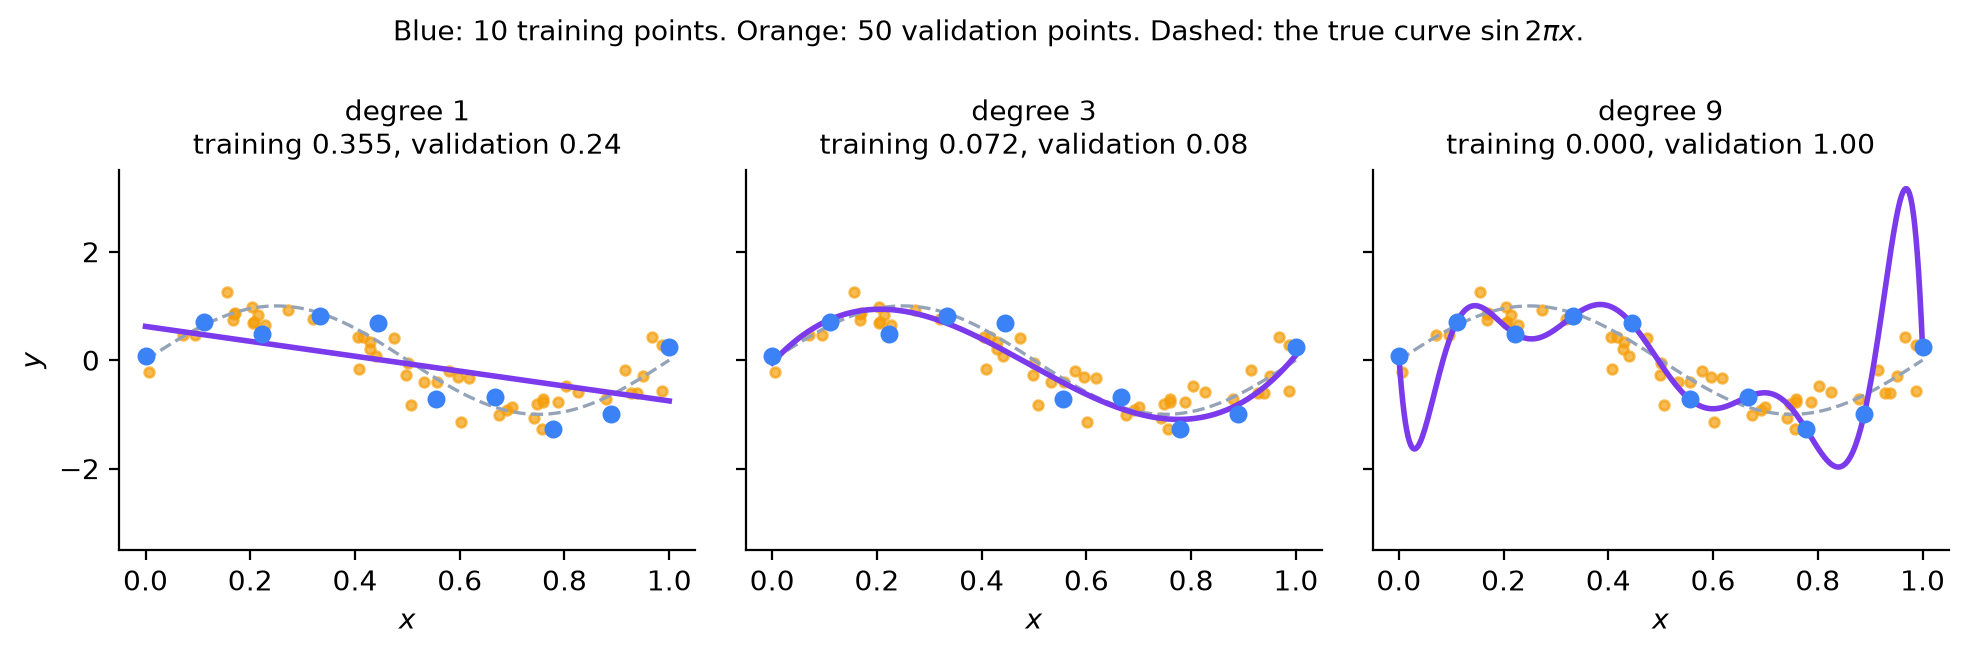

In [3]:
_show_mpl(_lessonfigs.polynomial_fits())

*Three snapshots of the same experiment. Degree 1 underfits (training 0.355, validation 0.24), degree 3 matches the shape (training 0.072, validation 0.08), degree 9 interpolates the noise (training 0.000, validation 1.00).*

```{mermaid}
graph LR
  D["All data"] --> S{"Split once"}
  S --> T["Training set"]
  S --> V["Validation set"]
  S --> X["Test set"]
  T --> F["Fit parameters by descent"]
  F --> C["Compare models on validation"]
  V --> C
  C --> R["Report once on test"]
  X --> R
```

*An honest workflow. Parameters are fitted on training data, choices such as degree or step size are made on validation data, and the test set is used once, at the end.*

:::{warning} What a low loss does not show
A low validation error shows good prediction for new data from the same source. It does not show that the model is causal: a model can predict well from a symptom of the outcome and still fail when we intervene. Level 4 makes this precise ([L4-10](#lesson-l4-10)). The U-shaped validation curve is a common empirical pattern, not a theorem; very large models trained in particular ways can behave differently.
:::

## Compute it

Gradient descent on the line-through-the-origin example. The exact minimizer is $23/14$; each step multiplies the error by $1 - \eta L'' = 1 - 0.1 \cdot \tfrac{28}{3} = \tfrac{1}{15}$.


In [4]:
from fractions import Fraction

# Fit y = w x to (1, 2), (2, 3), (3, 5) by minimizing L(w) = (1/3) * sum (w x - y)^2
xs, ys = [1, 2, 3], [2, 3, 5]
L = lambda w: sum((w * x - y) ** 2 for x, y in zip(xs, ys)) / 3
dL = lambda w: 2 * sum(x * (w * x - y) for x, y in zip(xs, ys)) / 3

w_star = Fraction(sum(x * y for x, y in zip(xs, ys)), sum(x * x for x in xs))
print('exact minimizer w* =', w_star, '=', round(float(w_star), 4), ' L(w*) =', round(L(float(w_star)), 4))

w, eta = 0.0, 0.1
for k in range(1, 6):
    w = w - eta * dL(w)
    print(f'step {k}: w = {w:.4f}, L = {L(w):.4f}, error = {w - float(w_star):+.2e}')
print('error shrinks by 1 - eta * L\'\' =', round(1 - eta * 28 / 3, 4), 'per step; stable while eta <', round(2 / (28 / 3), 3))

exact minimizer w* = 23/14 = 1.6429  L(w*) = 0.0714
step 1: w = 1.5333, L = 0.1274, error = -1.10e-01
step 2: w = 1.6356, L = 0.0717, error = -7.30e-03
step 3: w = 1.6424, L = 0.0714, error = -4.87e-04
step 4: w = 1.6428, L = 0.0714, error = -3.25e-05
step 5: w = 1.6429, L = 0.0714, error = -2.16e-06
error shrinks by 1 - eta * L'' = 0.0667 per step; stable while eta < 0.214


The step sizes of the animation, and two more. Watch the factor $1 - 8\eta$: below $-1$ the loss grows.


In [5]:
import numpy as np

# L(w) = w1^2 + 4 w2^2: each step multiplies w1 by (1 - 2 eta) and w2 by (1 - 8 eta)
def descend(eta, w=(-4.0, 1.2), steps=12):
    w = np.array(w)
    for _ in range(steps):
        w = w - eta * np.array([2 * w[0], 8 * w[1]])
    return w

for eta in (0.02, 0.1, 0.2, 0.24, 0.26):
    w = descend(eta)
    print(f'eta = {eta:<5} factors ({1 - 2 * eta:+.2f}, {1 - 8 * eta:+.2f})  after 12 steps L = {w[0]**2 + 4 * w[1]**2:10.4f}')
print('start L =', round((-4.0) ** 2 + 4 * 1.2 ** 2, 4), '; stable iff eta < 2 / 8 =', 2 / 8)

eta = 0.02  factors (+0.96, +0.84)  after 12 steps L =     6.0943
eta = 0.1   factors (+0.80, +0.20)  after 12 steps L =     0.0756
eta = 0.2   factors (+0.60, -0.60)  after 12 steps L =     0.0001
eta = 0.24  factors (+0.52, -0.92)  after 12 steps L =     0.7786
eta = 0.26  factors (+0.48, -1.08)  after 12 steps L =    36.5252
start L = 21.76 ; stable iff eta < 2 / 8 = 0.25


The overfitting experiment of the animation and the figure: same seed, same recipe. Training error never rises with degree; validation error does.


In [6]:
from numpy.polynomial import Polynomial

rng = np.random.default_rng(132)
x_train = np.linspace(0, 1, 10)
y_train = np.sin(2 * np.pi * x_train) + rng.normal(0, 0.3, 10)
x_val = rng.uniform(0, 1, 50)
y_val = np.sin(2 * np.pi * x_val) + rng.normal(0, 0.3, 50)

print('degree  training MSE  validation MSE')
for d in range(10):
    p = Polynomial.fit(x_train, y_train, d)          # least squares on the training points only
    tr = np.mean((p(x_train) - y_train) ** 2)
    va = np.mean((p(x_val) - y_val) ** 2)
    print(f'{d:>6}  {tr:12.4f}  {va:14.4f}')

degree  training MSE  validation MSE
     0        0.5471          0.4518
     1        0.3547          0.2396
     2        0.3520          0.2312
     3        0.0724          0.0848
     4        0.0507          0.1206
     5        0.0502          0.1201
     6        0.0491          0.1263
     7        0.0318          0.1699
     8        0.0204          0.2016
     9        0.0000          1.0045


:::{prf:remark} Gradients in larger models
For models with millions of parameters the gradient is computed by automatic differentiation (backpropagation), and each step usually uses a random batch of data (stochastic gradient descent). The stability lesson carries over: the step size must respect the steepest curvature of the loss. For parameterized quantum circuits, gradients can be estimated on hardware with parameter-shift rules [@schuld].
:::

## Worked example

:::{admonition} Two gradient steps by hand
:class: tip

For the line $\hat y = wx$ through $(1, 2), (2, 3), (3, 5)$ with $L(w) = \tfrac13\sum_i (wx_i - y_i)^2$, start at $w_0 = 0$ and take two gradient descent steps with $\eta = 0.1$. Compare with the exact minimizer, and find the largest stable step size.

1. Gradient: $L'(w) = \tfrac23(14w - 23)$, so $L'(0) = -\tfrac{46}{3} \approx -15.333$ and $L(0) = \tfrac{38}{3} \approx 12.667$.
2. Step 1: $w_1 = 0 - 0.1 \times (-\tfrac{46}{3}) = \tfrac{23}{15} \approx 1.5333$, with $L(w_1) \approx 0.127$.
3. Step 2: $L'(w_1) = \tfrac23(14 \times \tfrac{23}{15} - 23) = -\tfrac{46}{45} \approx -1.022$, so $w_2 = \tfrac{23}{15} + 0.1022 \approx 1.6356$.
4. The exact minimizer is $w^* = 23/14 \approx 1.6429$. The error $w_k - w^*$ is multiplied by $1 - \eta L''$ each step, where $L'' = \tfrac{28}{3}$: $1 - 0.1 \times \tfrac{28}{3} = \tfrac{1}{15}$. Indeed $w_0 - w^* = -1.6429$, $w_1 - w^* = -0.1095$, $w_2 - w^* \approx -0.0073$.
5. By [](#prop-l3-09-quadratic) with $a = L'' = \tfrac{28}{3}$, descent is stable for $0 < \eta < 2/a = \tfrac{3}{14} \approx 0.214$.

**Result.** $w_1 \approx 1.5333$, $w_2 \approx 1.6356$, approaching $w^* = 23/14 \approx 1.6429$ with the error divided by 15 at each step; any $\eta$ above $3/14 \approx 0.214$ would diverge.
:::

## Exercises

**1. (Core)** Let $L(w) = (w - 3)^2$. Starting from $w_0 = 0$ with $\eta = 0.25$, compute $w_1$, $w_2$ and $w_3$. By what factor does the distance to the minimum shrink each step?

:::{dropdown} Solution
$L'(w) = 2(w - 3)$. $w_1 = 0 - 0.25 \times (-6) = 1.5$; $w_2 = 1.5 - 0.25 \times (-3) = 2.25$; $w_3 = 2.25 - 0.25 \times (-1.5) = 2.625$. The distance to 3 goes $3, 1.5, 0.75, 0.375$: it halves each step, since $1 - \eta a = 1 - 0.25 \times 2 = 0.5$.
:::

**2. (Core)** For $L(w) = w_1^2 + 4w_2^2$ at $w = (-4, 1.2)$, compute $L$, the gradient, and one gradient step with $\eta = 0.1$. How much did $L$ drop?

:::{dropdown} Solution
$L = 16 + 4 \times 1.44 = 21.76$. $\nabla L = (2w_1, 8w_2) = (-8, 9.6)$. New $w = (-4 + 0.8,\ 1.2 - 0.96) = (-3.2, 0.24)$, and $L = 10.24 + 4 \times 0.0576 = 10.4704$. The loss roughly halved, dropping by $11.2896$.
:::

**3. (Stretch)** For $L = w_1^2 + 4w_2^2$, which single step size $\eta$ makes the slowest coordinate converge as fast as possible? That is, minimize $\max(|1 - 2\eta|, |1 - 8\eta|)$. What is the resulting factor?

:::{dropdown} Solution
As $\eta$ grows, $|1 - 2\eta|$ falls (for $\eta < 0.5$) while $|1 - 8\eta|$ falls until $\eta = 0.125$ and then rises. The maximum is smallest where $1 - 2\eta = -(1 - 8\eta)$, giving $10\eta = 2$, $\eta = 0.2$. Both factors then have size $0.6$ ($1 - 0.4 = 0.6$ and $1 - 1.6 = -0.6$). In general the best fixed step for curvatures $a_{\min}, a_{\max}$ is $2/(a_{\min} + a_{\max})$, with factor $(a_{\max} - a_{\min})/(a_{\max} + a_{\min})$; here $6/10$.
:::

**4. (Stretch)** For a line through the origin $\hat y = wx$ and data $(x_i, y_i)$, derive $w^* = \sum x_i y_i / \sum x_i^2$ from $L'(w) = 0$, and show that $w^*$ is a fixed point of gradient descent for every $\eta$.

:::{dropdown} Solution
$L(w) = \tfrac1n\sum(wx_i - y_i)^2$ gives $L'(w) = \tfrac2n\sum x_i(wx_i - y_i) = \tfrac2n\big(w\sum x_i^2 - \sum x_i y_i\big)$. Setting it to zero gives $w^* = \sum x_i y_i / \sum x_i^2$ (assuming not all $x_i$ are 0). Since $L'' = \tfrac2n\sum x_i^2 > 0$, this is a minimum. At $w^*$ the gradient is 0, so $w^* - \eta \cdot 0 = w^*$: the iteration stays put.
:::

**5. (Challenge)** Under the assumptions of [](#thm-l3-09-descent), with $\eta = 1/M$ and $f$ bounded below by $f_{\min}$, show that $\sum_{k=0}^{K-1} f'(w_k)^2 \le 2M\,\big(f(w_0) - f_{\min}\big)$ for every $K$. What does this imply about $f'(w_k)$ as $k$ grows, and what does it not imply?

:::{dropdown} Solution
The theorem gives $f(w_{k+1}) \le f(w_k) - \tfrac{1}{2M} f'(w_k)^2$, that is $f'(w_k)^2 \le 2M\,(f(w_k) - f(w_{k+1}))$. Summing over $k = 0, \dots, K-1$ telescopes: $\sum f'(w_k)^2 \le 2M\,(f(w_0) - f(w_K)) \le 2M\,(f(w_0) - f_{\min})$. A convergent series of non-negative terms has terms tending to 0, so $f'(w_k) \to 0$ and the smallest gradient among the first $K$ steps is at most $\sqrt{2M(f(w_0) - f_{\min})/K}$. It does not imply that $w_k$ approaches a global minimum: a zero gradient can occur at a local minimum or a flat point.
:::

**6. (Challenge)** In the overfitting experiment the degree-9 polynomial has training error 0 but validation error 1.00. Explain from [](#prop-l3-09-nested) why the training curve must fall to 0, and give two reasons why the validation curve need not follow it. Then propose a procedure for choosing the degree that uses the data honestly.

:::{dropdown} Solution
The polynomial families are nested, so the best training error cannot increase with degree, and with 10 distinct inputs a degree-9 polynomial interpolates every point, giving 0. Validation error need not follow because (1) the extra freedom is spent fitting the noise in the 10 training labels, which does not repeat in new data, and (2) between and beyond the training inputs a high-degree polynomial can swing far from the true curve. An honest procedure: fit each degree on the training set only, pick the degree with the lowest validation error (here 3, with 0.08), optionally refit on training plus validation, and report the error on a separate test set used once. With little data, $k$-fold cross-validation repeats the split $k$ times and averages.
:::

## Check your understanding

**1. For $L(w) = w^2$, start at $w = 3$ with step size $\eta = 0.1$. What is $w$ after one gradient descent step?**

- **A.** 2.9
- **B.** 2.4
- **C.** 3.6
- **D.** 2.7

:::{dropdown} Show the answer
**B. 2.4**

$L'(3) = 6$, so $w \leftarrow 3 - 0.1 \times 6 = 2.4$. The update moves against the gradient, toward the minimum at 0.
:::

**2. Gradient descent is run on $L(w) = w_1^2 + 4w_2^2$. Which step size makes it diverge?**

- **A.** 0.1
- **B.** 0.2
- **C.** 0.02
- **D.** 0.3

:::{dropdown} Show the answer
**D. 0.3**

The curvatures are 2 and 8, so descent converges only for $\eta < 2/8 = 0.25$. At $\eta = 0.3$ the $w_2$ factor is $1 - 2.4 = -1.4$, so $w_2$ flips sign and grows. Smaller steps converge, $0.02$ slowly.
:::

**3. A degree-9 polynomial has zero training error on 10 points. What is the best conclusion?**

- **A.** Gradient descent must have found the true curve
- **B.** Nothing yet about prediction: check its error on data it was not fitted to
- **C.** It is the best possible model for these data
- **D.** Its validation error must also be zero

:::{dropdown} Show the answer
**B. Nothing yet about prediction: check its error on data it was not fitted to**

With 10 distinct inputs a degree-9 polynomial always interpolates, so zero training error is guaranteed and says nothing about new data. In the lesson's experiment its validation error is 1.00, the worst of all degrees.
:::

**4. What is the gradient of $f(x, y) = x^2 + 4y^2$ at the point $(1, 1)$?** *(Review of [L3-06](#lesson-l3-06))*

- **A.** $(5, 5)$
- **B.** $(2, 4)$
- **C.** $(1, 4)$
- **D.** $(2, 8)$

:::{dropdown} Show the answer
**D. $(2, 8)$**

$\partial f/\partial x = 2x = 2$ and $\partial f/\partial y = 8y = 8$ at $(1, 1)$. The gradient points uphill, so gradient descent steps along $-(2, 8)$.
:::

## Common misconceptions

- **"The model with the lowest training loss is the best model."** Training loss can always be lowered by adding parameters, down to zero for an interpolating model. Prediction quality must be measured on data not used for fitting, such as a validation set.
- **"A larger step size always trains faster."** Only up to the stability limit. On a quadratic, steps beyond $2/a_{\max}$ make the iterates oscillate and grow, as $\eta = 0.26$ does for $L = w_1^2 + 4w_2^2$.
- **"Gradient descent always finds the global minimum."** It follows local slope information. On a convex bowl like the quadratics here it does converge (with a suitable step), but on non-convex losses it can stop at a local minimum or slow down near a flat saddle.

:::{caution} Scope and limits
The convergence proof is exact for quadratic losses and the descent theorem needs a bound on the curvature; real losses are rarely quadratic and often not convex, so these results describe local behavior near a minimum. The overfitting experiment is a single simulation with one seed and 50 validation points; its validation errors are estimates with their own sampling error, and the U shape is a typical pattern rather than a law. Stochastic gradients, momentum and adaptive step sizes are not covered. Good validation performance supports prediction on similar data, not causal conclusions.
:::

:::{seealso} Where this leads
Fitted predictive models return in [L4-10](#lesson-l4-10), where causal machine learning must ask whether predictions survive interventions and shifts, and in Level 7, where variational quantum circuits are trained by the same update ([L7-02](#lesson-l7-02)) [@vqa] and can meet flat landscapes called barren plateaus ([L7-04](#lesson-l7-04)) [@plateaus]. [L3-10](#lesson-l3-10) quantifies the sampling error of any estimate computed from finite data, and a validation error is such an estimate.
:::

:::{dropdown} For instructors

**Why this lesson.** Students who meet gradient descent only as a black-box optimizer miss both why it can fail (step size against curvature) and why success on training data is weak evidence. The separable quadratic gives an exact, checkable theory of step sizes, and the polynomial experiment makes overfitting visible and numerical [@mml; @openstax_derivative].

**Teaching notes.**

- Before the step-size animation, ask students to predict what happens at $\eta = 0.26$ on $L = w_1^2 + 4w_2^2$; many expect convergence because $0.26$ is close to $0.25$. Then compute the factor $-1.08$ together.
- Have students do the worked example with fractions; the error factor $1/15$ makes the geometric convergence visible without a calculator.
- Run the overfitting code with a different seed and compare the best validation degree across the class; this shows that validation errors are themselves noisy estimates, leading into L3-10.
- Connect the descent theorem to the tangent-line picture of L3-06: the curvature bound limits how far the function can bend away from its tangent within one step.

**Assessment.** The first two check questions test the update and the stability condition; the third tests the central conceptual point. The stretch exercise on the best step size and the challenge on summed gradients show whether students can reason with the factors $1 - \eta a_i$ rather than only compute them.

**Going further.** Add momentum, $v \leftarrow \beta v - \eta \nabla L$, $w \leftarrow w + v$, and study numerically how it speeds up the long valley of $L = w_1^2 + 4w_2^2$. Deisenroth, Faisal and Ong, chapter 7, treat gradient descent, step sizes and momentum [@mml].

:::

## References

This lesson draws on [@mml; @openstax_derivative; @openstax_gradient; @vqa; @schuld; @plateaus].

**Further reading.**

- [@mml]: Chapter 7 (continuous optimization) and chapter 8 (when models meet data) cover gradient descent, model selection and validation.
- [@plateaus]: Shows how flat loss landscapes can stall gradient training of quantum circuits.

**Next:** [L3-10 · Estimation, intervals, and repeated tests](#lesson-l3-10)
